In [147]:
library(tidyverse)
library(tximport)
library(DESeq2)
library(rtracklayer)
library(edgeR)
library(ggrepel)
library(RColorBrewer)

In [2]:
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15), rect=element_rect(linewidth=1)))

In [5]:
#GENCODE annotations
gtf.file <- "/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.gtf.gz"
gencode <- import(gtf.file)
gencode <- gencode[which(gencode$type=="gene")]
#read in TSS coordinates w/ genes
gencode_tss <- read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.transcripts_tss.1kb.bed", header=F, sep='\t')

#ENSEMBL canonical TSS set for protein-coding transcripts (stricter set used for mapping coordinates of invariant promoters)
ensembl_tss <- read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/ENSEMBL/ensembl.canonical.prot-coding.transcript.tss1kb.bed", header=F, sep='\t')

In [6]:
#generate rowdata

row.data <- data.frame(gencode@elementMetadata)
rownames(row.data) <- row.data$gene_id
row.data$gene_id <- NULL
#generate column with cleaned ENSEMBL IDs
row.data$gene_id_base <- gsub("\\..*$", "", rownames(row.data)) 
#remove NA columns
row.data <- row.data[,colSums(is.na(row.data))<nrow(row.data)]
# add genome coordinates
row.data$chr <- as.character(gencode@seqnames)
row.data$start <- as.numeric(gencode@ranges@start)
row.data$end <- row.data$start + as.numeric(gencode@ranges@width)

In [7]:
#read in data
dir <- "/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/RSEM/HepG2/"
files <- c(
    "rep1_dmso_1_anno_rsem.genes.results",
    "rep1_dmso_2_anno_rsem.genes.results",
    "rep1_brm_1_anno_rsem.genes.results",
    "rep1_brm_2_anno_rsem.genes.results"
    )
txi <- tximport(files=paste0(dir,files), txIn=F, type="rsem")


reading in files with read_tsv

1 
2 
3 
4 




In [8]:
#filter txi object

nrow(txi$abundance)
#first, filter to exclude non-protein coding genes using the row metadata
txi$abundance <- txi$abundance[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$abundance))),] 
txi$counts <- txi$counts[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$counts))),]
txi$length <- txi$length[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$length))),]
nrow(txi$abundance)
#next, filter to remove lowly-expressed and 0-length genes
filt <- which(apply(txi$abundance,MARGIN=1,FUN=max) <= 1 | #genes with low expression (where max TPM for all samples is <=1)
                apply(txi$length, MARGIN=1,FUN=min)==0) #genes with weird annotations (length=0)

#filter out these genes from txi object
txi$abundance <- txi$abundance[-filt,]
txi$counts <- txi$counts[-filt,]
txi$length <- txi$length[-filt,]

#get rid of any NA rows
txi$counts <- txi$counts[-which(!rowSums(is.finite(txi$abundance))),]
txi$length <- txi$length[-which(!rowSums(is.finite(txi$abundance))),]
txi$abundance <- txi$abundance[-which(!rowSums(is.finite(txi$abundance))),]
nrow(txi$abundance)
     
#filter row metadata to match rows of filtered txi object
row.data <- row.data[match(gsub("\\..*$", "", 
                                rownames(txi$abundance)), 
                           row.data$gene_id_base),]
nrow(txi$abundance)
nrow(row.data)

[1] 59526

[1] 78724

[1] 14214

[1] 14214

[1] 14214

In [9]:
#make coldata
col.data <- data.frame("condition"=c("dmso", "dmso", "brm", "brm"), rep=c(1,2,1,2))

In [10]:
#run DESeq2
dds <- DESeqDataSetFromTximport(txi, colData=col.data, design = ~condition)
des <- DESeq(dds)
res <- results(des, contrast=c("condition", "brm", "dmso"))
res <- res %>% data.frame() %>% mutate(change=case_when(
    log2FoldChange > log2(1.5) & padj < .05 ~ "up",
    log2FoldChange < -log2(1.5) & padj < .05 ~ "down", 
    TRUE ~ "nc"))

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [ ]:
res %>% ggplot(aes(x=log2FoldChange,y=-log10(padj), fill=change)) + 
    geom_point(shape=21) + geom_vline(xintercept=c(-1,1), linetype=2) + geom_hline(yintercept=-log10(.05), linetype=2) +
    scale_fill_manual(values=c("nc"="grey", "down"="blue", "up"="red"), name="sig.diff") + 
    geom_text_repel(data=(data.frame(res) %>% mutate(gene_name=row.data$gene_name))[which(res$padj < .05 & abs(res$log2FoldChange)>2),], aes(label=gene_name)) + 
    ggtitle("BRM014 vs DMSO", subtitle=paste("n=", nrow(res), "\n", "down:", nrow(res[which(res$padj < .05 & res$log2FoldChange < -1), ]),"; up:", nrow(res[which(res$padj < .05 & res$log2FoldChange > 1), ])))

In [18]:
#Identify genes that are unchanging with BRM014 treatment
#Criteria: p.adj > 0.2, 0.8 < fold change < 1.2
no_change <- which(res$padj > 0.2 & res$log2FoldChange > log2(.8) & res$log2FoldChange < log2(1.2))
#get genome coordinates for nc promoters
row.data_nc <- row.data[no_change,] %>% filter(!is.na(gene_name))

In [19]:
#make GRanges of non-changing gene coordinates
row.data_nc_gr <- GRanges(seqnames=row.data_nc$chr, ranges=IRanges(start=row.data_nc$start, end=row.data_nc$end))

#consensus peak set, filtered and with cRE type annotations (from ../filtered/filter_peaks.ipynb)
consensus_annot <- read.delim("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/HepG2/filtered/hepg2_consensus_filt_annot.tsv",sep='\t')
consensus_annot_gr <- GRanges(seqnames=consensus_annot$seqnames, ranges=IRanges(start=consensus_annot$start, end=consensus_annot$end))

#TSS annotations for invariant genes
tss_nc <- ensembl_tss[ensembl_tss$V4 %in% row.data$gene_name[no_change],]
tss_nc_gr <- GRanges(seqnames=tss_nc$V1, ranges=IRanges(start=tss_nc$V2, end=tss_nc$V3))

#filter consensus_annot to only include promoters that overlap with coordinates of invariantly expressed genes
consensus_filt <- consensus_annot[which(countOverlaps(consensus_annot_gr, tss_nc_gr) > 0 ),] %>% filter(type=="prom")
write.table(consensus_filt[,1:3] %>% mutate(ID=seq(1,nrow(consensus_filt))), "hepg2_invariant_promoters_24h.bed", row.names=F, col.names=F,quote=F, sep='\t')

In [11]:
countmat_control <- read.delim("~/projects/poised_enh_manuscript/inputs/countmat/HepG2/hepg2_invariant_promoters.tsv", sep='\t', header=F)
sizes <- colSums(countmat_control[,5:8])
countmat<- read.delim("~/projects/poised_enh_manuscript/inputs/countmat/HepG2/hepg2_consensus_filt.tsv", sep='\t', header=F)
counts <- countmat[,5:8]

In [12]:
dar <- function(data, coldata) {
    library(edgeR)
  
  # Create DGEList object with counts and group information
    dge <- DGEList(counts = data, group = coldata$Condition)
  
  # Override default library size with effective library sizes from control regions
    dge$samples$lib.size <- coldata$sizes
  
  # Set normalization factors to 1 (i.e., use lib.size as-is with no further scaling)
    dge$samples$norm.factors <- rep(1, nrow(coldata))
  
  # Create design matrix for comparison (model without intercept, group-specific columns)
    design <- model.matrix(~0 + group, data = dge$samples)
    colnames(design) <- levels(dge$samples$group)  # optional: label columns by condition names
  
  # Estimate dispersion 
    dge <- estimateDisp(dge, design)
  
  # Fit generalized linear model (GLM) 
    dge_fit <- glmQLFit(dge, design)
  
  # Conduct differential test (treatment vs control)
    diff <- glmQLFTest(dge_fit, contrast = c(1, -1))
  
  # Return all regions without sorting; include logFC, p-value, FDR, etc.
    res <- topTags(diff, n = Inf, sort.by = "none")$table 
  # Add column categorizing peaks as gaining, losing, or not changing accessibility
    res <- res %>% mutate(
                    change = case_when(FDR < 0.05 & logFC > log2(1.5) ~ "up",
                                       FDR < 0.05 & logFC < -log2(1.5) ~ "down",
                                       TRUE ~ "nc"))
  return(res)
}

In [13]:
coldata <- data.frame("Condition"=c("dmso", "dmso", "brm", "brm"), "Replicate"=c(1,2,1,2), "sizes"=sizes)

In [71]:
#using default library size normalization

dge <- DGEList(counts=counts, group=coldata$Condition)
dge <- calcNormFactors(dge)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge$samples)
dge <- estimateDisp(dge, design)

#run DAR analysis
dge_fit <- glmQLFit(dge)
diff <- glmQLFTest(dge_fit, contrast=c(1,-1))
res <- topTags(diff, n=Inf)$table %>% mutate(
                    change = case_when(FDR < 0.05 & logFC > log2(1.5) ~ "up",
                                       FDR < 0.05 & logFC < -log2(1.5) ~ "down",
                                       TRUE ~ "nc"))

In [72]:
#summarize # that change (gain/lose accessibility) or do not using this method
res %>% group_by(change) %>% summarize(n())

change,n()
<chr>,<int>
down,36155
nc,90135
up,22583


In [73]:
#now using invariant promoter counts as effective library sizes
res_norm <- dar(counts, coldata)

In [74]:
#count as above
res_norm %>% group_by(change) %>% summarize(n()) 


change,n()
<chr>,<int>
down,52094
nc,89638
up,7141


In [75]:
#sanity check on control regions
dge_control <- DGEList(counts=countmat_control[,5:8], group=coldata$Condition)
dge_control <- calcNormFactors(dge_control)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge_control$samples)
dge_control <- estimateDisp(dge_control, design)

#run DAR analysis
dge_control_fit <- glmQLFit(dge_control)
diff_control <- glmQLFTest(dge_control_fit, contrast=c(1,-1))
res_control <- topTags(diff_control, n=Inf)$table %>% mutate(
                    change = case_when(FDR < 0.05 & logFC > log2(1.5) ~ "up",
                                       FDR < 0.05 & logFC < -log2(1.5) ~ "down",
                                       TRUE ~ "nc"))

In [76]:
res_control %>% group_by(change) %>% summarize(n()) 

change,n()
<chr>,<int>
down,368
nc,4152
up,12


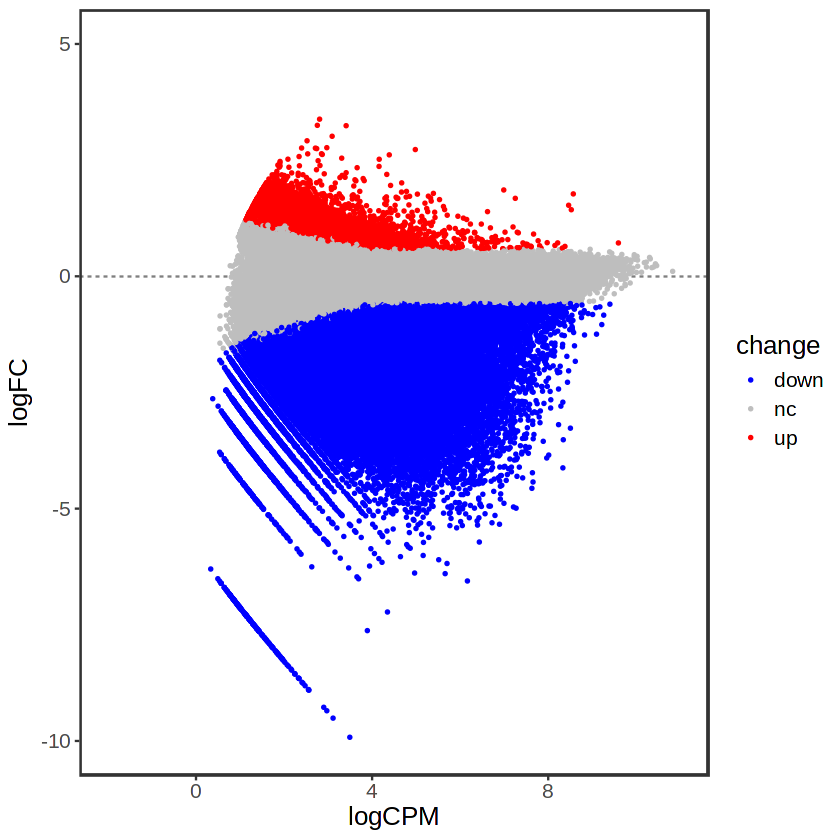

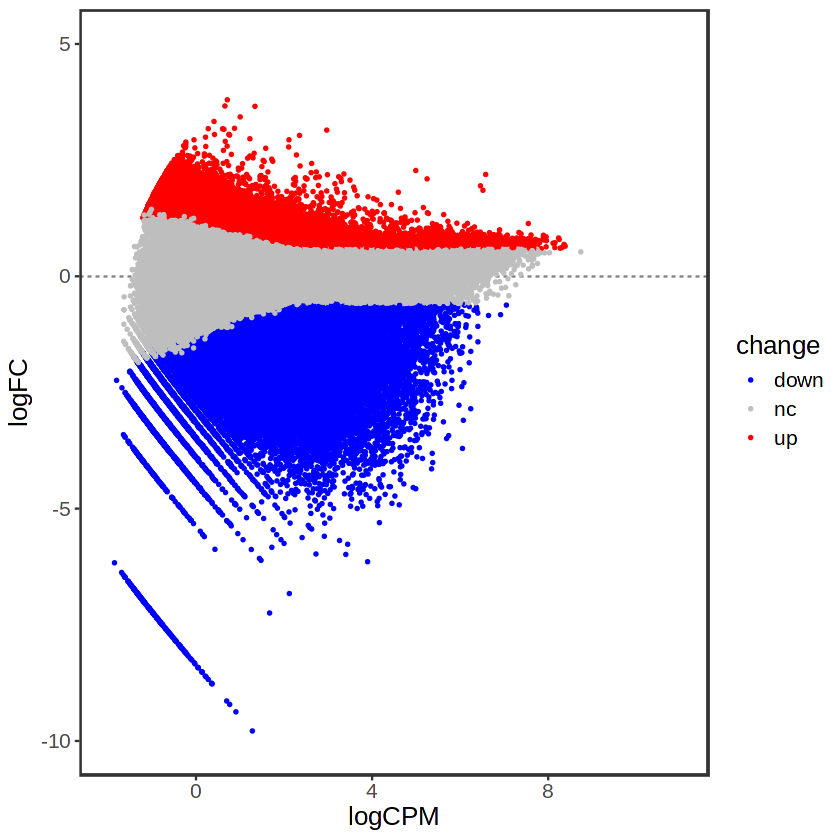

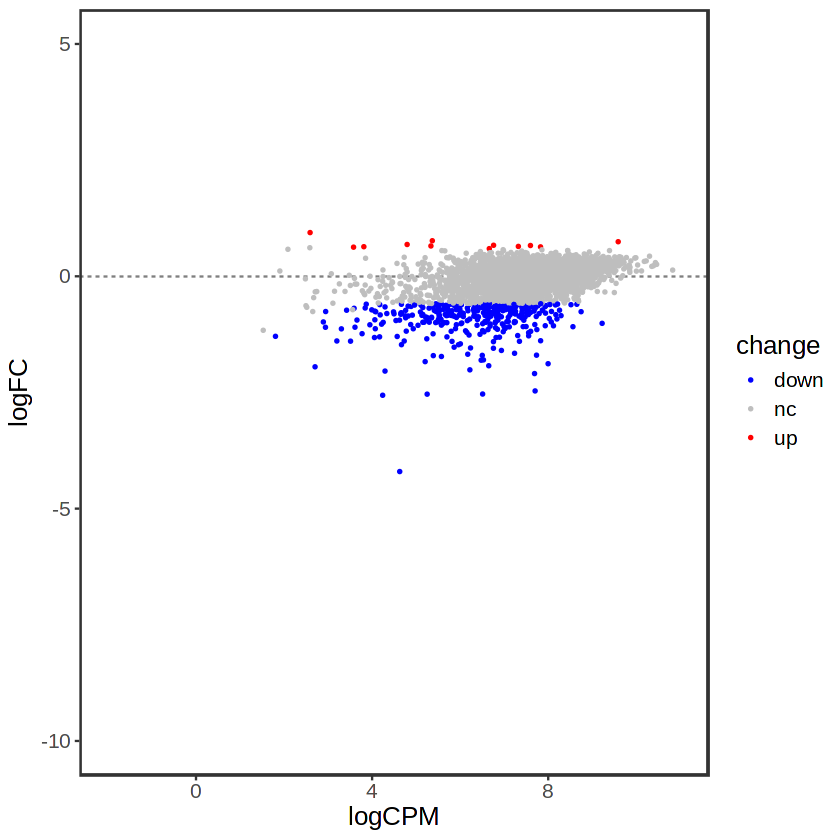

In [77]:
#res_control %>% ggplot(aes(x=logFC,y=-log10(FDR))) + geom_point(shape=21,aes(fill=change)) + scale_fill_manual(values=c("nc"="grey", "down"="blue", "up"="red"))  geom_vline(xintercept=c(-1,1)) + geom_hline(yintercept=-log10(.05))
res_norm %>% ggplot(aes(y=logFC,x=logCPM))  + geom_hline(yintercept=0,linetype=2, color="grey50") + geom_point(aes(color=change), size=.5) + scale_color_manual(values=c("nc"="grey", "down"="blue", "up"="red")) + ylim(-10,5) + xlim(-2,11)
res %>% ggplot(aes(y=logFC,x=logCPM))  + geom_hline(yintercept=0,linetype=2, color="grey50") + geom_point(aes(color=change), size=.5) + scale_color_manual(values=c("nc"="grey", "down"="blue", "up"="red")) + ylim(-10,5) + xlim(-2,11)
res_control %>% ggplot(aes(y=logFC,x=logCPM))  + geom_hline(yintercept=0,linetype=2, color="grey50") + geom_point(aes(color=change), size=.5) + scale_color_manual(values=c("nc"="grey", "down"="blue", "up"="red")) + ylim(-10,5) + xlim(-2,11)


In [ ]:
res_norm %>% group_by(type=consensus_annot$type, change) %>% summarize(n=n()) %>% ungroup() %>% group_by(type) %>% summarize(change, n, pct=100*n/sum(n)) %>% 
    ggplot(aes(y=type, x=pct, fill=change)) + geom_col(color="black", width=.5) + scale_fill_manual(values=c("nc"="grey", "down"="blue", "up"="red"))

res_norm %>% group_by(type=consensus_annot$type, change) %>% summarize(n=n()) %>% ungroup() %>% group_by(type) %>% summarize(change, n, pct=100*n/sum(n)) %>% 
    ggplot(aes(y=type, x=n, fill=change)) + geom_col(color="black", position=position_dodge()) + scale_fill_manual(values=c("nc"="grey", "down"="blue", "up"="red"))

In [ ]:
res_norm %>% group_by(type=consensus_annot$type) %>% ggplot(aes(y=reorder(type, logFC),x=logFC)) + geom_vline(xintercept=0) + geom_violin(fill="darkgrey") + geom_boxplot(width=.1, outlier.shape=NA, fill="black", color="white", linewidth=.2)

res_norm %>% mutate(type=consensus_annot$type) %>% 
    mutate(type=case_when(grepl("enh", type) ~ "enh", grepl("other", type) ~ "other", type=="CTCF_only" ~ "CTCF", type=="prom" ~ "prom")) %>% ggplot(aes(y=reorder(type, -logFC),x=logFC)) + geom_vline(xintercept=0) + geom_violin(fill="darkgrey") + geom_boxplot(width=.1, outlier.shape=NA, fill="black", color="white", linewidth=.2) + coord_flip()

In [15]:
dir_2 <- "/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bigwig/ENCODE/HepG2/"
feats <- c("CHD4", "CTCF", "DPF2", "H3K27ac", "H3K27me3", "H3K4me1", "H3K4me3", "HDAC2")

In [113]:
consensus_annot_2 <- consensus_annot %>% select(seqnames,start,end,TSS,ID, type, H3K4me1_bed=H3K4me1) %>% mutate(lfc=res_norm$logFC, fdr=res_norm$FDR, change=res_norm$change)
for(feat in feats){
    temp <- read.delim(paste0(dir_2,feat, ".tab"), sep='\t', header=F) %>% arrange(V1)
    consensus_annot_2[[feat]] <- temp$V6
}

In [ ]:
consensus_annot_2 %>% select(!c(seqnames, start,end,TSS, ID, lfc, fdr, change)) %>% pivot_longer(!type) %>% group_by(type, name) %>% 
    summarize(mean=mean(value)) %>% pivot_wider(names_from=name, values_from=mean) %>% column_to_rownames("type") %>% t()  %>% 
    pheatmap(color=colorRampPalette(colors=rev(brewer.pal(7, "RdBu")))(100), scale="row", border_color=NA, cluster_rows=FALSE, cluster_cols=FALSE, main="HepG2, z-scored")

consensus_annot_2 %>% select(!c(seqnames, start,end,TSS, ID, lfc, fdr, change)) %>% pivot_longer(!type) %>% group_by(type, name) %>% 
    summarize(mean=mean(value)) %>% pivot_wider(names_from=name, values_from=mean) %>% column_to_rownames("type") %>% t()  %>% 
    pheatmap(color=colorRampPalette(colors=(brewer.pal(7, "Reds")))(100), border_color=NA, cluster_rows=FALSE, cluster_cols=FALSE,
            main="HepG2")

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 2726 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 828 rows containing missing values or values outside the scale range
(`geom_point()`).”


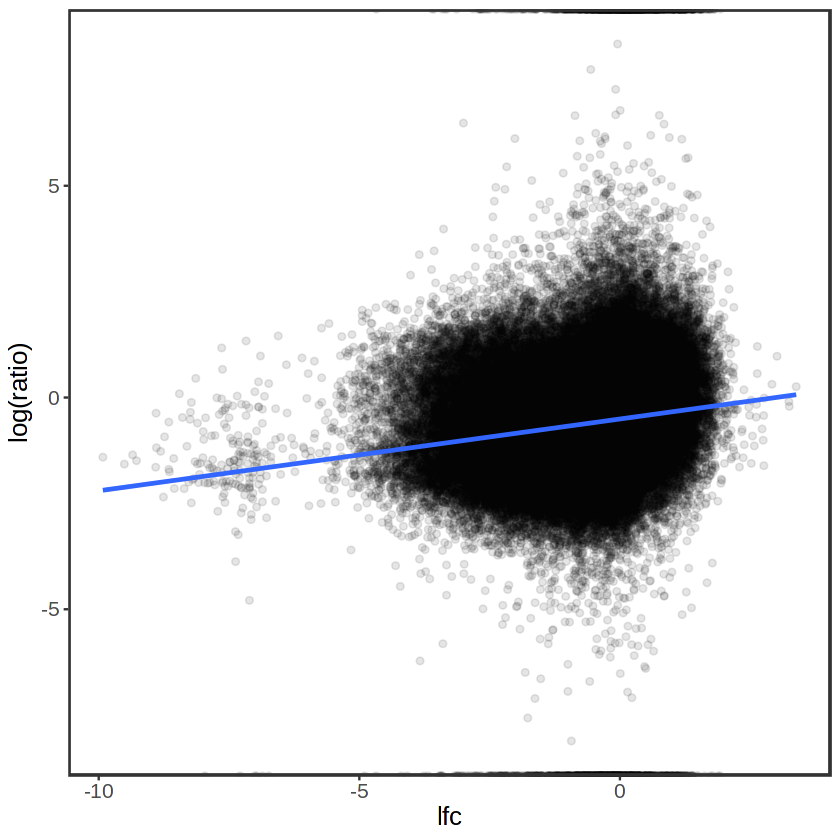

In [21]:
data.frame(lfc=res_norm$logFC, TSS=consensus_annot$TSS, change=res_norm$change, ratio=consensus_annot_2$H3K27ac/consensus_annot_2$H3K4me1) %>% filter(TSS==FALSE) %>% 
    ggplot(aes(x=lfc, y=log(ratio))) + geom_point(alpha=.1) + geom_smooth(method=lm)

In [145]:
#question - is there a quantitative relationship between the ratio of H3K27ac/H3K4me1 (high ratio ~ active, low ratio ~ poised) and change in accessibility due to BAFinh?

p1 <- data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>%
    filter(TSS==FALSE) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=lfc)) + 
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2, ) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    geom_hline(yintercept=0, linetype=2) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean log2 fold change in accessibility") + 
    ggtitle("log2(H3K27ac/H3K4me1)")

p2 <- data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>%
    filter(TSS==FALSE) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=H3K4me1)) + 
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1), geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean H3K4me1") + 
    ggtitle("H3K4me1")


p3 <- data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>%
    filter(TSS==FALSE) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=H3K27ac)) + 
    stat_summary(fun.data = mean_se,fun.args = list(mult = 1), geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean H3K27ac") + 
    ggtitle("H3K27ac")


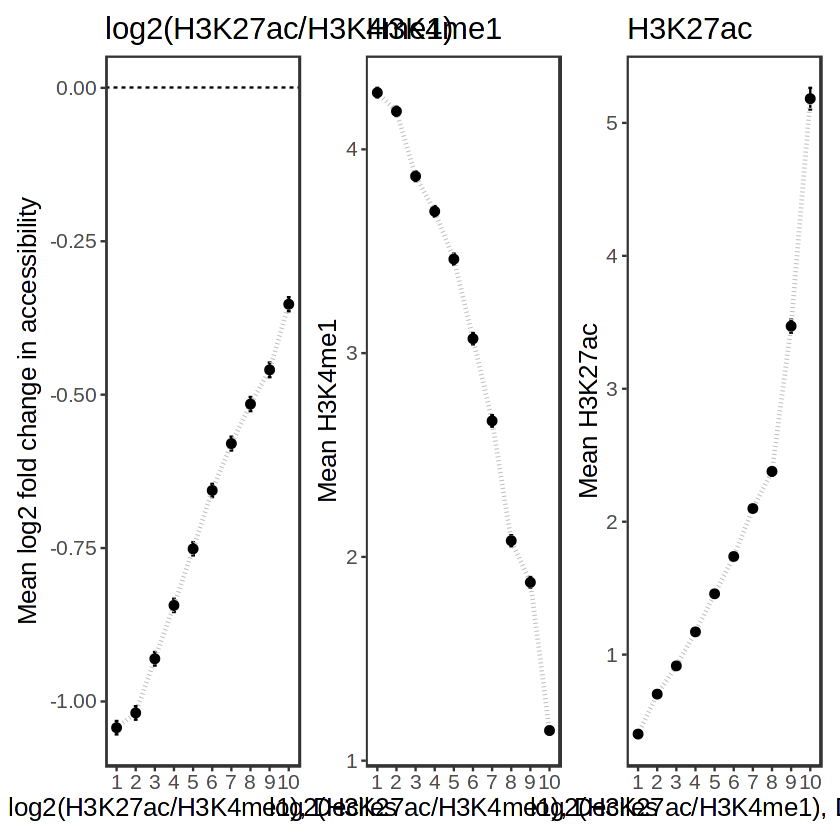

In [69]:
library(patchwork)
p1 | p2 | p3
#ggsave("ratio.pdf", width=12, height=4)

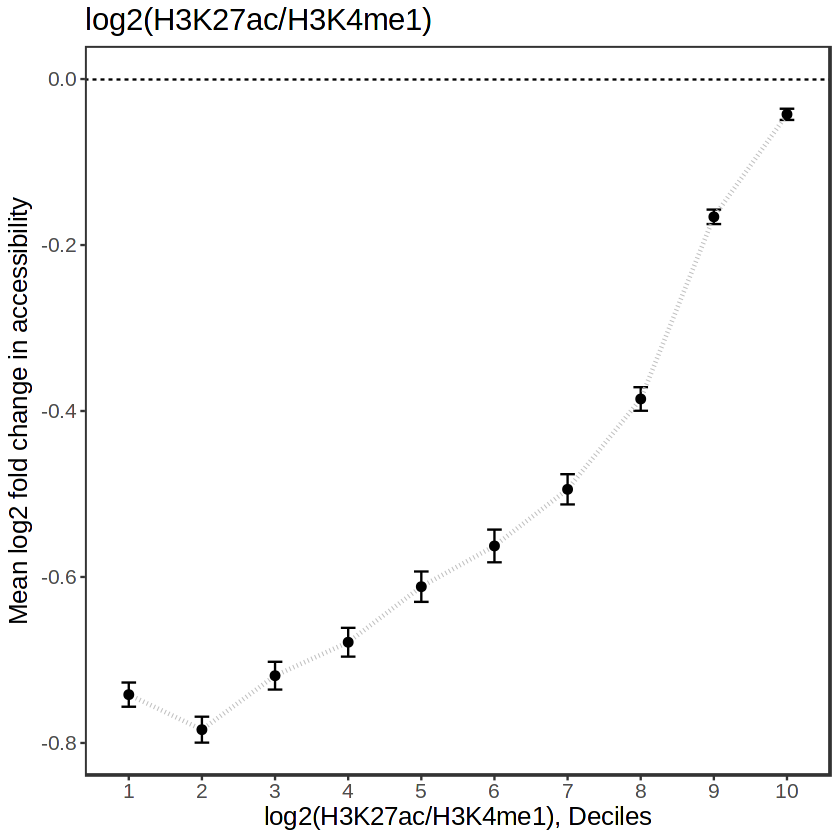

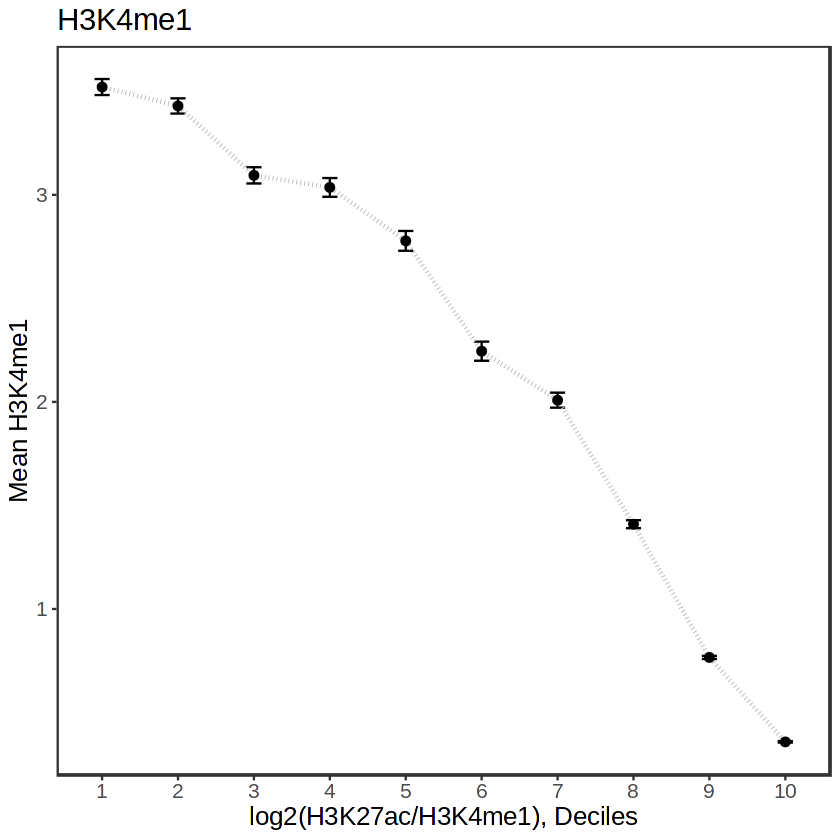

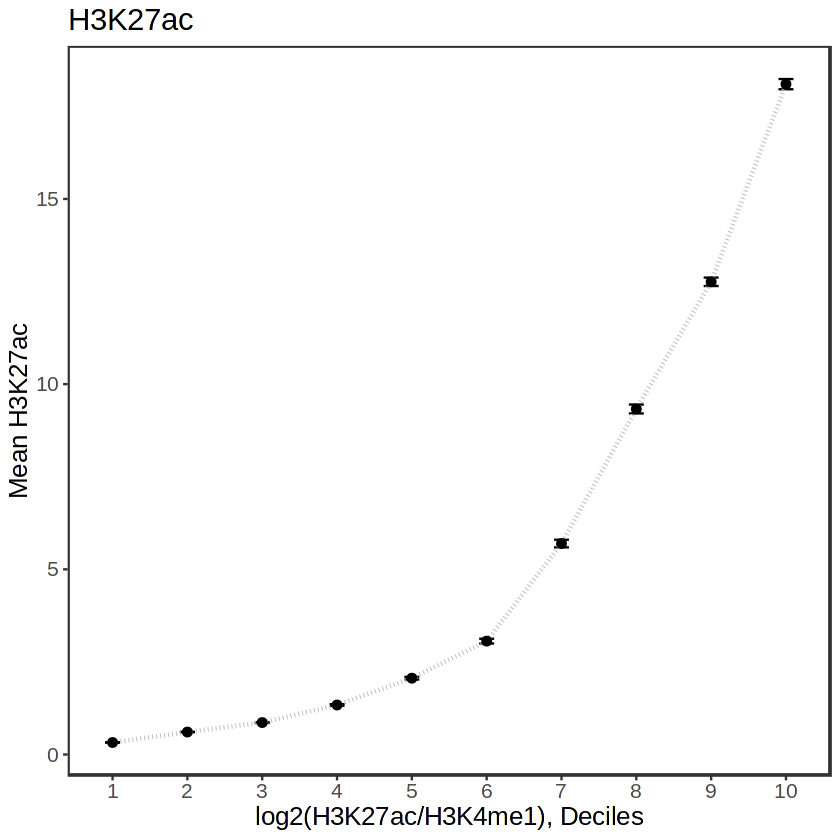

In [144]:
#same analysis as above but at TSS-proximal sites

data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>%
    filter(TSS==TRUE) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=lfc)) + 
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2, ) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    geom_hline(yintercept=0, linetype=2) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean log2 fold change in accessibility") + 
    ggtitle("log2(H3K27ac/H3K4me1)")

data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>%
    filter(TSS==TRUE) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=H3K4me1)) + 
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1), geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean H3K4me1") + 
    ggtitle("H3K4me1")


data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>%
    filter(TSS==TRUE) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=H3K27ac)) + 
    stat_summary(fun.data = mean_se,fun.args = list(mult = 1), geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean H3K27ac") + 
    ggtitle("H3K27ac")

In [33]:
#using a complementary approach of fitting a linear model

model <- glm(lfc ~ ratio, 
    data=data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))))
summary(model)


Call:
glm(formula = lfc ~ ratio, data = data.frame(lfc = res_norm$logFC, 
    TSS = consensus_annot$TSS, change = res_norm$change, H3K4me1 = consensus_annot_2$H3K4me1, 
    H3K27ac = consensus_annot_2$H3K27ac, ratio = log2((consensus_annot_2$H3K27ac + 
        0.01)/(consensus_annot_2$H3K4me1 + 0.01))))

Deviance Residuals: 
    Min       1Q   Median       3Q      Max  
-9.0937  -0.5679   0.2158   0.7487   3.9520  

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) -0.609172   0.003044 -200.10   <2e-16 ***
ratio        0.107630   0.001369   78.62   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for gaussian family taken to be 1.293436)

    Null deviance: 200551  on 148872  degrees of freedom
Residual deviance: 192555  on 148871  degrees of freedom
AIC: 460793

Number of Fisher Scoring iterations: 2


In [107]:
test <- consensus_annot_2 %>% 
    mutate(ratio=log2((H3K27ac+.01)/(H3K4me1+.01)), lfc=res_norm$logFC) %>% 
    filter(!type %in% c("prom", "other_TSS")) 
a <- lm(lfc ~ ratio, data=test) %>% summary()
b <- lm(lfc ~ H3K27ac, data=test) %>% summary()
c <- lm(lfc ~ ratio  + CTCF + DPF2   , data=test) %>% summary()
d <- lm(lfc ~ H3K27ac  + CTCF + DPF2   , data=test) %>% summary()

In [108]:
a$coefficients
a$adj.r.squared
b$coefficients
b$adj.r.squared
c$coefficients
c$adj.r.squared
d$coefficients
d$adj.r.squared

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-0.6055293,0.003950471,-153.28028,0
ratio,0.1253480,0.002014319,62.22848,0


[1] 0.03283606

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-0.52661751,0.0038546579,-136.6185,0
H3K27ac,-0.09650798,0.0009021953,-106.9702,0


[1] 0.0911896

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-0.05004431,0.0061207346,-8.176193,2.959224e-16
ratio,0.13082846,0.0017762348,73.654939,0.000000e+00
CTCF,0.02774408,0.0004502029,61.625729,0.000000e+00
DPF2,-0.45869617,0.0028372411,-161.669788,0.000000e+00


[1] 0.2486019

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-0.18323779,0.0059921574,-30.57960,1.544935e-204
H3K27ac,-0.03324407,0.0009590799,-34.66247,6.752397e-262
CTCF,0.02671645,0.0004605762,58.00657,0.000000e+00
DPF2,-0.39922279,0.0032818738,-121.64477,0.000000e+00


[1] 0.22106

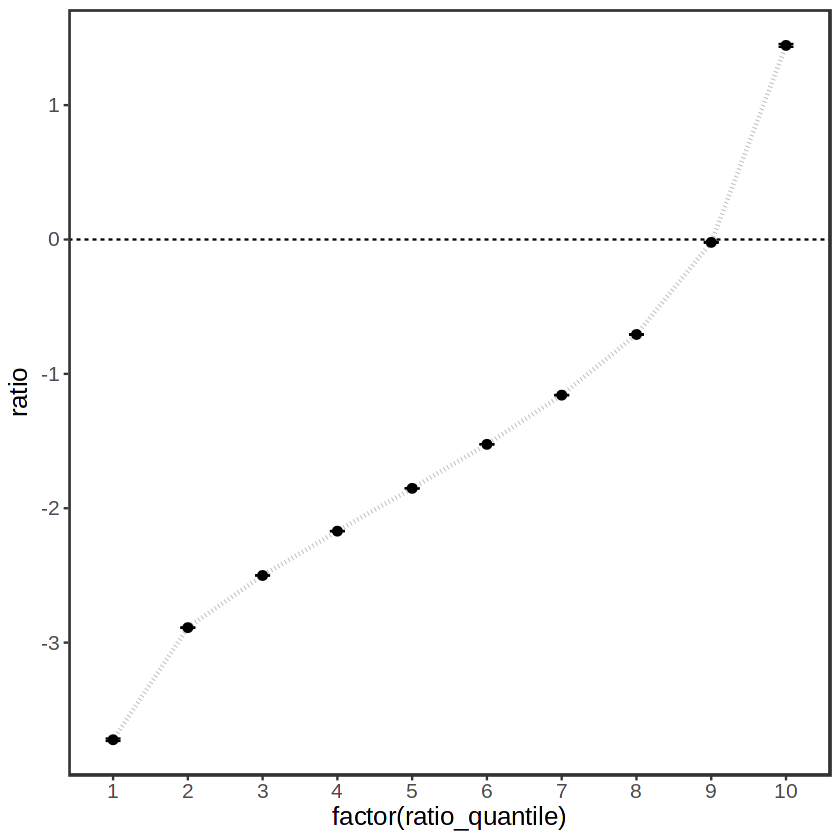

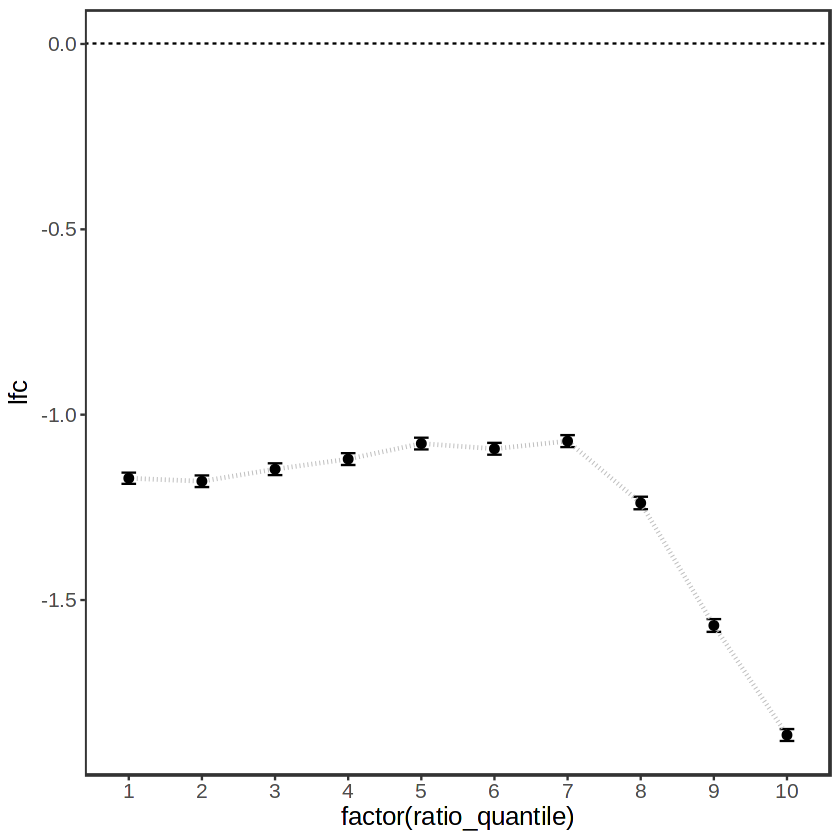

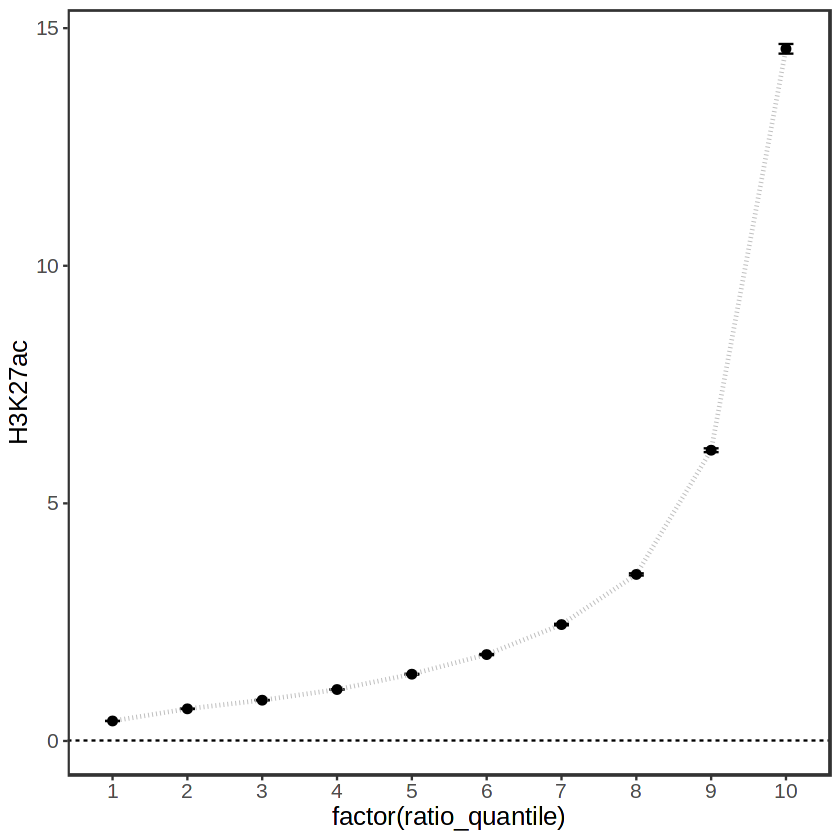

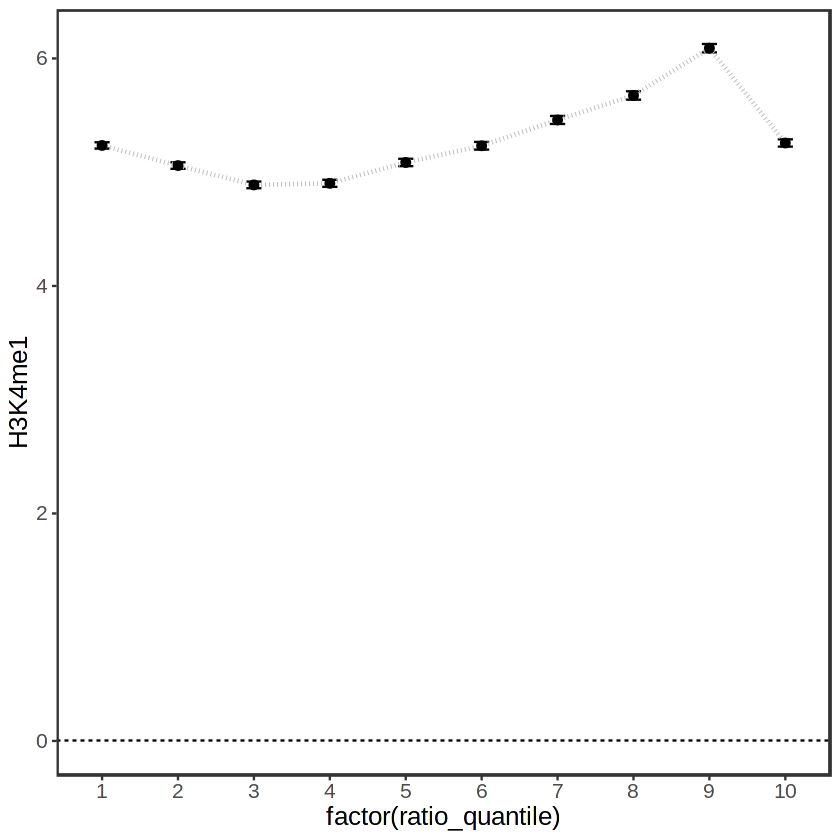

In [141]:
consensus_annot_2 %>% filter(TSS==FALSE, H3K4me1_bed==TRUE) %>% mutate(ratio=log2((H3K27ac+.01)/(H3K4me1+.01))) %>% mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=ratio)) + geom_hline(yintercept=0, linetype=2) +
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2)

consensus_annot_2 %>% filter(TSS==FALSE, H3K4me1_bed==TRUE) %>% mutate(ratio=log2((H3K27ac+.01)/(H3K4me1+.01))) %>% mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=lfc)) + geom_hline(yintercept=0, linetype=2) +
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2)

consensus_annot_2 %>% filter(TSS==FALSE, H3K4me1_bed==TRUE) %>% mutate(ratio=log2((H3K27ac+.01)/(H3K4me1+.01))) %>% mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=H3K27ac)) + geom_hline(yintercept=0, linetype=2) +
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2)

consensus_annot_2 %>% filter(TSS==FALSE, H3K4me1_bed==TRUE) %>% mutate(ratio=log2((H3K27ac+.01)/(H3K4me1+.01))) %>% mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=H3K4me1)) + geom_hline(yintercept=0, linetype=2) +
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2)

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 38 rows containing non-finite outside the scale range
(`stat_smooth()`).”


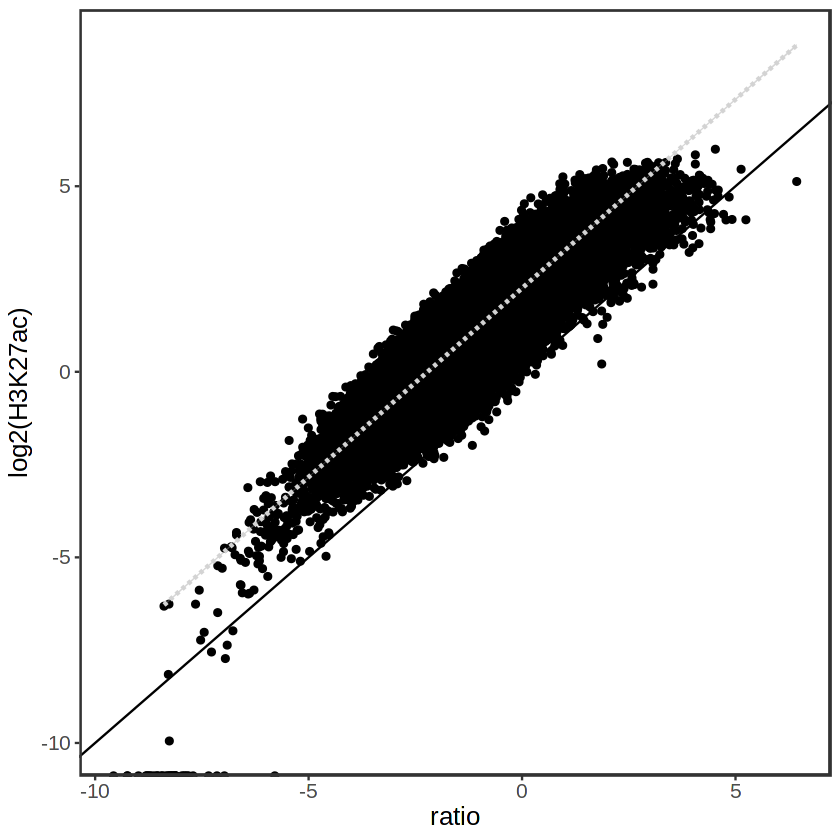

In [140]:
consensus_annot_2 %>% filter(TSS==FALSE, H3K4me1_bed==TRUE) %>% mutate(ratio=log2((H3K27ac+.01)/(H3K4me1+.01))) %>% ggplot(aes(x=ratio,y=log2(H3K27ac))) + geom_point() + geom_abline() + geom_smooth(method=lm, color="lightgrey", linetype=2)

In [146]:
consensus_annot_2 %>% filter(TSS==FALSE, H3K4me1_bed==TRUE) %>% mutate(ratio=log2((H3K27ac+.01)/(H3K4me1+.01))) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>% 
    group_by(ratio_quantile) %>% summarize(mean(lfc), mean(CTCF))

ratio_quantile,mean(lfc),mean(CTCF)
<int>,<dbl>,<dbl>
1,-1.171425,3.622476
2,-1.179589,3.987240
3,-1.147064,4.076847
4,-1.119771,4.089726
5,-1.077929,3.688620
6,-1.092013,3.587882
7,-1.071307,3.331379
8,-1.238281,2.964439
9,-1.568689,2.595986


In [151]:
consensus_annot_2

seqnames,start,end,TSS,ID,type,H3K4me1_bed,lfc,fdr,change,CHD4,CTCF,DPF2,H3K27ac,H3K27me3,H3K4me1,H3K4me3,HDAC2
<chr>,<int>,<int>,<lgl>,<int>,<chr>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr1,10057,10729,TRUE,1,other_TSS,FALSE,-0.266646092,3.665291e-01,nc,1.068000,0.185502,0.222602,0.35635800,0.1162750,0.00000000,0.000000,0.191791
chr1,180771,181914,TRUE,2,other_TSS,FALSE,0.067290427,7.744371e-01,nc,2.144000,0.562687,0.608123,0.25208000,0.0832966,0.08440380,0.601541,0.447804
chr1,196465,196638,FALSE,3,other_nonTSS,FALSE,-0.208845712,7.428670e-01,nc,0.000000,0.000000,0.000000,0.00000000,0.0000000,0.00000000,0.000000,0.000000
chr1,778479,779251,TRUE,4,prom,FALSE,-0.003752818,9.764434e-01,nc,2.242320,11.874600,1.137590,14.60300000,0.4110700,0.23543700,29.241200,6.064060
chr1,804737,805012,FALSE,5,other_nonTSS,FALSE,-0.444902974,4.265453e-01,nc,0.263180,0.897842,0.000000,0.00000000,0.2364160,0.67332400,0.261480,0.735601
chr1,826872,828105,TRUE,6,prom,FALSE,0.034798051,7.645906e-01,nc,0.775488,1.368680,0.701190,8.32308000,0.4231790,0.12198200,27.443600,3.803490
chr1,850257,850669,FALSE,7,other_nonTSS,FALSE,0.275325836,5.717155e-01,nc,0.304383,3.575680,0.360451,0.47550300,0.1034740,0.00813981,0.000000,1.335700
chr1,856720,857002,FALSE,8,other_nonTSS,FALSE,-0.579861126,2.295440e-01,nc,0.627717,1.312540,1.082450,0.00192688,0.2481830,1.57370000,0.141840,1.016440
chr1,857932,859012,TRUE,9,prom,FALSE,-0.549772256,3.599545e-02,nc,0.641897,4.749520,1.775600,1.08638000,0.5306660,1.08753000,5.654930,1.410490


In [165]:
#write output

consensus_annot %>% select(seqnames,start,end,TSS,ID, type)  %>% mutate(lfc=res_norm$logFC, fdr=res_norm$FDR, change=res_norm$change) %>% 
    write.table("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/HepG2/filtered/hepg2_consensus_filt_annot_dar.tsv", col.names=TRUE, row.names=FALSE, quote=FALSE, sep='\t')